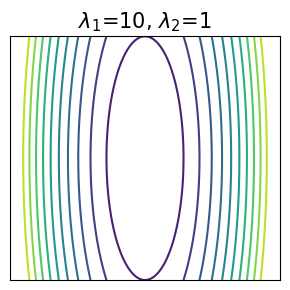

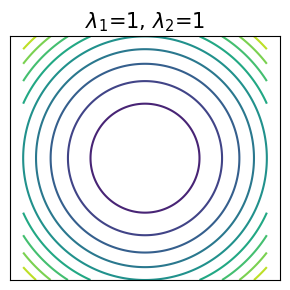

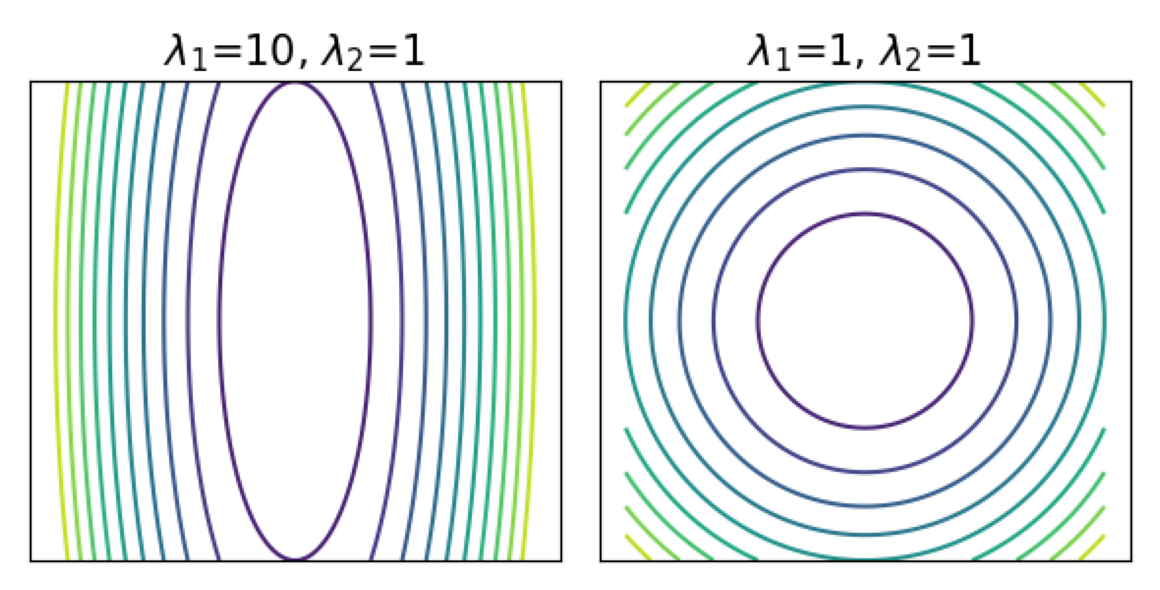

Saved files:
./anisotropic.png
./isotropic.png
./anisotropic_isotropic.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Save directory
save_dir = "."
anisotropic_path = f"{save_dir}/anisotropic.png"
isotropic_path = f"{save_dir}/isotropic.png"
combined_path = f"{save_dir}/anisotropic_isotropic.png"

# Grid
x = np.linspace(-100, 100, 400)
y = np.linspace(-100, 100, 400)
X, Y = np.meshgrid(x, y)

# Quadratic forms
# Anisotropic: different curvature along each axis
Z_aniso = 10 * X**2 + 1 * Y**2

# Isotropic: same curvature along each axis
Z_iso = X**2 + Y**2

# -----------------------------
# 1. Anisotropic plot
# -----------------------------
plt.figure(figsize=(3, 3))
plt.contour(X, Y, Z_aniso, levels=10)
# plt.xlabel("x")
# plt.ylabel("y")
plt.title(f"$\lambda_1$=10, $\lambda_2$=1", fontsize=15)
plt.axis("equal")
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.savefig(anisotropic_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# -----------------------------
# 2. Isotropic plot
# -----------------------------
plt.figure(figsize=(3, 3))
plt.contour(X, Y, Z_iso, levels=10)
# plt.xlabel("x")
# plt.ylabel("y")
plt.xticks([])
plt.yticks([])
plt.title(f"$\lambda_1$=1, $\lambda_2$=1", fontsize=15)
plt.axis("equal")
plt.tight_layout()
plt.savefig(isotropic_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# -----------------------------
# 3. Combine two saved images
# -----------------------------
img1 = Image.open(anisotropic_path)
img2 = Image.open(isotropic_path)

# Match heights
target_height = max(img1.height, img2.height)

if img1.height != target_height:
    new_width = int(img1.width * target_height / img1.height)
    img1 = img1.resize((new_width, target_height))

if img2.height != target_height:
    new_width = int(img2.width * target_height / img2.height)
    img2 = img2.resize((new_width, target_height))

combined = Image.new("RGB", (img1.width + img2.width, target_height), "white")
combined.paste(img1, (0, 0))
combined.paste(img2, (img1.width, 0))
combined.save(combined_path)

# Show combined image
plt.figure(figsize=(12, 6))
plt.imshow(combined)
plt.axis("off")
# plt.title("Anisotropic vs Isotropic")
plt.tight_layout()
plt.show()

print("Saved files:")
print(anisotropic_path)
print(isotropic_path)
print(combined_path)

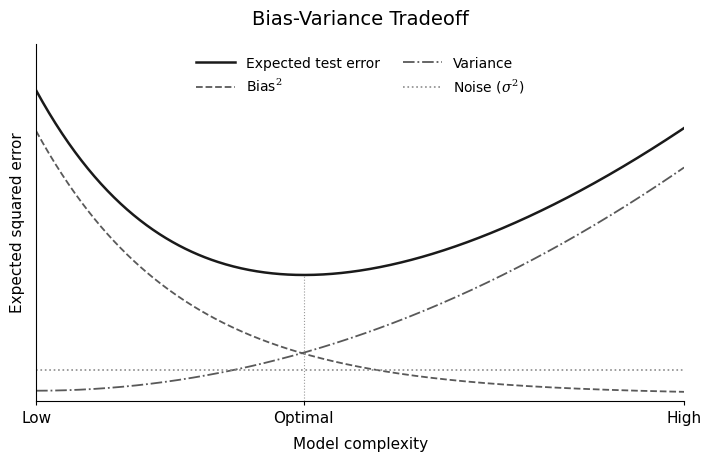

Saved: /Users/johnsmac/Downloads/python/github/johnjaejunlee95ko/images/26-10-17/bias_variance_tradeoff.png


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Illustrative curves for squared-error regression.
complexity = np.linspace(0, 1, 500)
bias_squared = 1.3 * np.exp(-4.5 * complexity) + 0.03
variance = 0.05 + 1.1 * complexity**2
noise = np.full_like(complexity, 0.15)
expected_test_error = bias_squared + variance + noise
best_index = np.argmin(expected_test_error)
best_complexity = complexity[best_index]

with plt.rc_context({
#     "font.family": "serif",
    "font.size": 11,
    "mathtext.fontset": "dejavuserif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
}):
    fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
    ax.plot(complexity, expected_test_error, color="0.1", linewidth=1.8,
            label="Expected test error")
    ax.plot(complexity, bias_squared, color="0.35", linewidth=1.3,
            linestyle="--", label=r"Bias$^2$")
    ax.plot(complexity, variance, color="0.35", linewidth=1.3,
            linestyle="-.", label="Variance")
    ax.plot(complexity, noise, color="0.55", linewidth=1.2,
            linestyle=":", label=r"Noise ($\sigma^2$)")
    ax.vlines(best_complexity, 0, expected_test_error[best_index],
              color="0.6", linewidth=0.8, linestyle=":")

    ax.set_title("Bias-Variance Tradeoff", fontsize=14, pad=14)
    ax.set_xlabel("Model complexity", labelpad=8)
    ax.set_ylabel("Expected squared error", labelpad=8)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, expected_test_error.max() * 1.15)
    ax.set_xticks([0, best_complexity, 1], ["Low", "Optimal", "High"])
    ax.set_yticks([])
    ax.tick_params(length=3, width=0.8)
    ax.legend(loc="upper center", ncol=2, frameon=False, fontsize=10,
              handlelength=2.8, columnspacing=1.6)

    # Saved in the current working directory, matching the earlier cell.
    output_path = Path("bias_variance_tradeoff.png")
    fig.savefig(output_path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

print(f"Saved: {output_path.resolve()}")


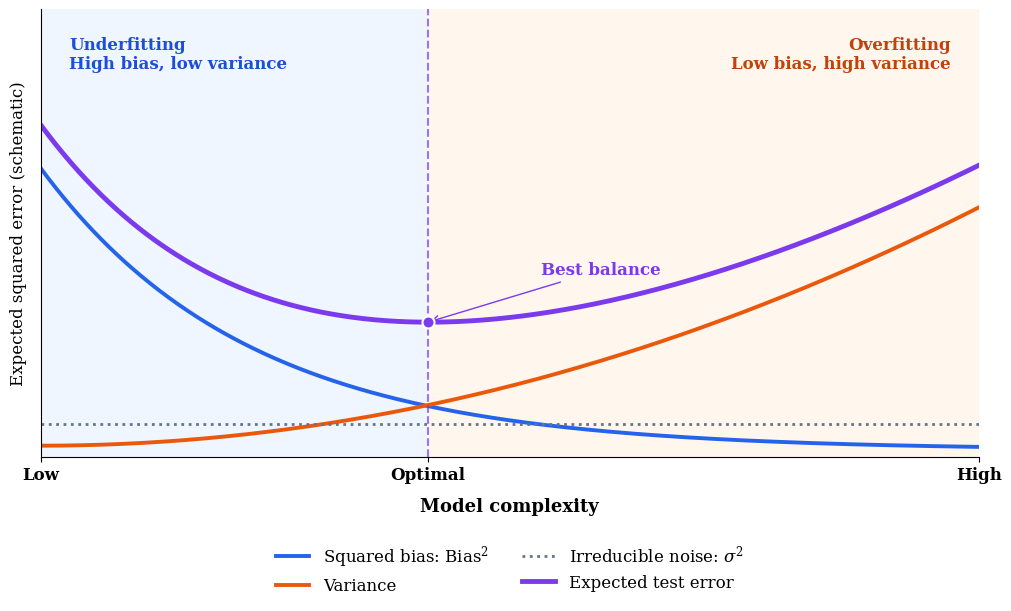

Saved: /Users/johnsmac/Downloads/python/github/johnjaejunlee95ko/images/26-10-17/bias_variance_tradeoff.png


In [26]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 개념 설명용 곡선
complexity = np.linspace(0, 1, 500)
bias_squared = 1.3 * np.exp(-4.5 * complexity) + 0.03
variance = 0.05 + 1.1 * complexity**2
noise = np.full_like(complexity, 0.15)
expected_test_error = bias_squared + variance + noise

best_index = np.argmin(expected_test_error)
best_complexity = complexity[best_index]

with plt.rc_context({
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
}):
    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

    # 과소적합 / 과적합 영역 음영
    ax.axvspan(0, best_complexity, color="#EFF6FF", zorder=0)
    ax.axvspan(best_complexity, 1, color="#FFF7ED", zorder=0)

    ax.plot(
        complexity, bias_squared,
        color="#2563EB", linewidth=2.8,
        label=r"Squared bias: $\mathrm{Bias}^2$",
    )
    ax.plot(
        complexity, variance,
        color="#EA580C", linewidth=2.8,
        label="Variance",
    )
    ax.plot(
        complexity, noise,
        color="#64748B", linewidth=2, linestyle=":",
        label=r"Irreducible noise: $\sigma^2$",
    )
    ax.plot(
        complexity, expected_test_error,
        color="#7C3AED", linewidth=3.5,
        label="Expected test error",
    )

    ax.axvline(
        best_complexity,
        color="#7C3AED", linestyle="--",
        linewidth=1.5, alpha=0.7,
    )
    ax.scatter(
        best_complexity, expected_test_error[best_index],
        s=75, color="#7C3AED",
        edgecolors="white", linewidths=1.5, zorder=5,
    )
    ax.annotate(
        "Best balance",
        xy=(best_complexity, expected_test_error[best_index]),
        xytext=(
            best_complexity + 0.12,
            expected_test_error[best_index] + 0.22,
        ),
        arrowprops={"arrowstyle": "->", "color": "#7C3AED"},
        color="#7C3AED", fontweight="bold",
    )

    # ax.set_title(
    #     "Bias–Variance Tradeoff",
    #     fontsize=22, fontweight="bold", pad=36,
    # )
    # ax.text(
    #     0.5, 1.035,
    #     r"$\mathbf{\mathbb{E}[(y-\hat{f}(x))^2]}"
    #     r" = \mathbf{\mathrm{Bias}[\hat{f}(x)]^2}"
    #     r" + \mathbf{\mathrm{Var}[\hat{f}(x)]} + \mathbf{\sigma^2}$",
    #     transform=ax.transAxes, ha="center", fontsize=13, fontweight="bold",
    # )
    ax.text(
        0.03, 0.94, 
        "Underfitting\nHigh bias, low variance",
        transform=ax.transAxes, va="top", color="#1D4ED8", fontweight="bold", fontsize=12,
    )
    ax.text(
        0.97, 0.94,
        "Overfitting\nLow bias, high variance",
        transform=ax.transAxes, ha="right", va="top", fontweight="bold", fontsize=12,
        color="#C2410C",
    )

    ax.set_xlabel("Model complexity", labelpad=10, fontsize=13, fontweight="bold")
    ax.set_ylabel("Expected squared error (schematic)", labelpad=10)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, expected_test_error.max() * 1.35)
    ax.set_xticks(
        [0, best_complexity, 1],
        ["Low", "Optimal", "High"], fontsize=12, fontweight="bold"
    )
    ax.set_yticks([])
    ax.legend(
        loc="upper center", bbox_to_anchor=(0.5, -0.16),
        ncol=2, frameon=False,
    )
    # fig.text(
    #     0.5, -0.08,
    #     "Illustrative curves; the shape depends on the data and model family.",
    #     ha="center", fontsize=10, color="#64748B",
    # )

    output_path = Path("bias_variance_tradeoff.png")
    fig.savefig(
        output_path, dpi=300,
        bbox_inches="tight", facecolor="white", 
    )
    plt.show()
    plt.close(fig)

print(f"Saved: {output_path.resolve()}")